# Zomato Food Delivery Analysis — AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026

**Author:** Ramanjot Kaur  
**Internship:** AICTE | IBM SkillsBuild Data Analytics with AI (2026)  
**Dataset:** Synthetic academic dataset based on a Zomato-like food delivery business context (10,000 cleaned orders)  

---

## 1. Introduction & Business Problem

### Business Context
Food delivery platforms operate on razor-thin margins. Revenue depends on order volume, average order value, delivery efficiency, and customer retention. A critical operational challenge is **late deliveries** — they drive negative ratings, cancellations, and customer churn.

### Business Problem
> **Can we predict whether a food delivery order will be late, and which operational and order-level factors drive late deliveries?**

Identifying the root causes of late delivery enables the business to:
- Prioritise high-risk orders for proactive intervention
- Optimise restaurant preparation time and delivery routing
- Improve customer satisfaction and reduce cancellations

### Project Objectives
1. Validate the cleaned dataset and document its quality
2. Perform Exploratory Data Analysis (EDA) to understand delivery patterns
3. Engineer features relevant to late delivery prediction
4. Train and evaluate a classification ML model (Logistic Regression + Random Forest)
5. Extract actionable business insights and recommendations
6. Document IBM Bob usage throughout the project

## 2. Setup & Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    ConfusionMatrixDisplay, roc_curve, accuracy_score, f1_score
)
from sklearn.pipeline import Pipeline

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Resolve file path — works whether notebook is run from any directory
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('Zomato_Food_Delivery_Analysis.ipynb'))
EXCEL_FILE = os.path.join(NOTEBOOK_DIR, 'Zomato Cleaned Datset RK.xlsx')

# Plot style
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11
})
PALETTE = '#E23744'

print('Libraries loaded successfully.')
print(f'Excel file path: {EXCEL_FILE}')

Libraries loaded successfully.
Excel file path: e:\Internships\rk\Zomato Cleaned Datset RK.xlsx


## 3. Dataset & Quality Validation

In [2]:
# Load the core columns (Cleaned Data sheet)
# Note: The workbook contains formula-based computed columns (Net Food Value, Delivery Variance,
# On Time Flag, Discount Band, Order Value Band) whose cached values are not stored.
# We load the raw measurement columns and recompute these fields in Python using the
# documented formulas from the 'Formula Guide' sheet.

RAW_COLS = [
    'Order_ID', 'Order_Date', 'Order_Time', 'Meal_Period', 'Customer_ID',
    'Customer_Name', 'Customer_Segment', 'Membership_Status', 'Order_Channel',
    'City', 'State', 'Region', 'Restaurant_ID', 'Restaurant_Name',
    'Restaurant_Tier', 'Cuisine', 'Dish', 'Item_Count',
    'Order_Value_INR', 'Offer_Type', 'Discount_Pct', 'Discount_Amount_INR',
    'Packaging_Fee_INR', 'Delivery_Charge_INR', 'Final_Amount_INR',
    'Delivery_Distance_KM', 'Preparation_Time_Min', 'Estimated_Delivery_Min',
    'Actual_Delivery_Min', 'Payment_Mode', 'Restaurant_Rating', 'Customer_Rating',
    'Order_Status'
]

df_raw = pd.read_excel(EXCEL_FILE, sheet_name='Cleaned Data',
                       usecols=RAW_COLS, engine='openpyxl')

print(f'Loaded shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')

Loaded shape: 10,000 rows x 33 columns


In [3]:
# Recompute the formula-based columns using documented logic from the Formula Guide sheet
df = df_raw.copy()

# Net Food Value = Order_Value_INR - Discount_Amount_INR
df['Net_Food_Value'] = df['Order_Value_INR'] - df['Discount_Amount_INR']

# Delivery Variance = Actual_Delivery_Min - Estimated_Delivery_Min
df['Delivery_Variance'] = df['Actual_Delivery_Min'] - df['Estimated_Delivery_Min']

# On Time Flag: if Delivery Variance <= 0 then 'On Time' else 'Late'
df['On_Time_Flag'] = np.where(df['Delivery_Variance'] <= 0, 'On Time', 'Late')

# Discount Band
def discount_band(pct):
    if pct == 0:
        return 'No Discount'
    elif pct <= 10:
        return '1-10%'
    elif pct <= 20:
        return '11-20%'
    else:
        return 'Above 20%'
df['Discount_Band'] = df['Discount_Pct'].apply(discount_band)

# Order Value Band
def order_value_band(val):
    if val < 300:
        return 'Under Rs 300'
    elif val <= 600:
        return 'Rs 300-600'
    elif val <= 1000:
        return 'Rs 601-1000'
    else:
        return 'Above Rs 1000'
df['Order_Value_Band'] = df['Order_Value_INR'].apply(order_value_band)

print('Computed columns:')
print(df[['Net_Food_Value', 'Delivery_Variance', 'On_Time_Flag',
          'Discount_Band', 'Order_Value_Band']].head())

Computed columns:
   Net_Food_Value  Delivery_Variance On_Time_Flag Discount_Band  \
0          116.77                 -6      On Time         1-10%   
1          540.82                  5         Late   No Discount   
2          465.46                  0      On Time        11-20%   
3         1231.66                 -2      On Time   No Discount   
4          889.87                 12         Late         1-10%   

  Order_Value_Band  
0     Under Rs 300  
1       Rs 300-600  
2       Rs 300-600  
3    Above Rs 1000  
4      Rs 601-1000  


In [4]:
print(f'Final dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Columns: {list(df.columns)}')

Final dataset shape: 10,000 rows x 38 columns
Columns: ['Order_ID', 'Order_Date', 'Order_Time', 'Meal_Period', 'Customer_ID', 'Customer_Name', 'Customer_Segment', 'Membership_Status', 'Order_Channel', 'City', 'State', 'Region', 'Restaurant_ID', 'Restaurant_Name', 'Restaurant_Tier', 'Cuisine', 'Dish', 'Item_Count', 'Order_Value_INR', 'Offer_Type', 'Discount_Pct', 'Discount_Amount_INR', 'Packaging_Fee_INR', 'Delivery_Charge_INR', 'Final_Amount_INR', 'Delivery_Distance_KM', 'Preparation_Time_Min', 'Estimated_Delivery_Min', 'Actual_Delivery_Min', 'Payment_Mode', 'Restaurant_Rating', 'Customer_Rating', 'Order_Status', 'Net_Food_Value', 'Delivery_Variance', 'On_Time_Flag', 'Discount_Band', 'Order_Value_Band']


In [5]:
df.head(3)

,Order_ID,Order_Date,Order_Time,Meal_Period,Customer_ID,Customer_Name,Customer_Segment,Membership_Status,Order_Channel,City,...,Actual_Delivery_Min,Payment_Mode,Restaurant_Rating,Customer_Rating,Order_Status,Net_Food_Value,Delivery_Variance,On_Time_Flag,Discount_Band,Order_Value_Band
0,ZOM200001,2025-06-13,15:33,Lunch,CZ11017,Customer 11017,Young Professional,Non-Member,App,Hyderabad,...,20,Debit Card,3.4,4.9,Delivered,116.77,-6,On Time,1-10%,Under Rs 300
1,ZOM200002,2024-08-08,18:43,Evening,CZ10273,Customer 10273,Family,Non-Member,App,Hyderabad,...,40,UPI,3.3,4.0,Delivered,540.82,5,Late,No Discount,Rs 300-600
2,ZOM200003,2026-02-01,13:59,Lunch,CZ13854,Customer 13854,Student,Gold,App,Pune,...,23,UPI,4.1,5.0,Delivered,465.46,0,On Time,11-20%,Rs 300-600


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                10000 non-null  str    
 1   Order_Date              10000 non-null  str    
 2   Order_Time              10000 non-null  str    
 3   Meal_Period             10000 non-null  str    
 4   Customer_ID             10000 non-null  str    
 5   Customer_Name           10000 non-null  str    
 6   Customer_Segment        10000 non-null  str    
 7   Membership_Status       10000 non-null  str    
 8   Order_Channel           10000 non-null  str    
 9   City                    10000 non-null  str    
 10  State                   10000 non-null  str    
 11  Region                  10000 non-null  str    
 12  Restaurant_ID           10000 non-null  str    
 13  Restaurant_Name         10000 non-null  str    
 14  Restaurant_Tier         10000 non-null  str    
 1

In [7]:
# Missing value audit
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_report = missing_report[missing_report['Missing Count'] > 0]
if missing_report.empty:
    print('No missing values found — dataset is complete.')
else:
    print(missing_report)

No missing values found — dataset is complete.


In [8]:
# Duplicate check
dup_count = df.duplicated(subset='Order_ID').sum()
print(f'Duplicate Order_IDs: {dup_count}')
print(f'Total unique orders: {df["Order_ID"].nunique():,}')

Duplicate Order_IDs: 0
Total unique orders: 10,000


In [9]:
# Numeric summary statistics
numeric_cols = [
    'Order_Value_INR', 'Discount_Pct', 'Discount_Amount_INR',
    'Packaging_Fee_INR', 'Delivery_Charge_INR', 'Final_Amount_INR',
    'Delivery_Distance_KM', 'Preparation_Time_Min',
    'Estimated_Delivery_Min', 'Actual_Delivery_Min',
    'Restaurant_Rating', 'Customer_Rating'
]
df[numeric_cols].describe().round(2)

,Order_Value_INR,Discount_Pct,Discount_Amount_INR,Packaging_Fee_INR,Delivery_Charge_INR,Final_Amount_INR,Delivery_Distance_KM,Preparation_Time_Min,Estimated_Delivery_Min,Actual_Delivery_Min,Restaurant_Rating,Customer_Rating
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,567.52,8.34,47.67,23.06,29.13,572.04,4.22,15.24,33.27,36.59,3.94,4.73
std,383.77,7.85,63.77,7.32,12.69,355.48,2.93,4.36,6.77,9.38,0.45,0.32
min,100.00,0.00,0.00,10.00,0.06,98.67,0.70,8.00,20.00,15.00,2.50,3.10
25%,288.21,0.00,0.00,16.85,20.22,314.34,2.00,12.00,28.00,30.00,3.60,4.50
50%,473.42,8.50,27.97,23.01,26.82,484.08,3.60,15.00,32.00,36.00,3.90,4.80
75%,739.21,14.20,71.50,29.23,36.02,729.10,5.70,18.00,37.00,42.00,4.20,5.00
max,3297.45,28.00,645.38,38.99,86.18,3099.97,16.00,39.00,66.00,78.00,5.00,5.00


In [10]:
# Categorical value counts
cat_cols = ['Order_Status', 'On_Time_Flag', 'Customer_Segment',
            'Membership_Status', 'Restaurant_Tier', 'Region',
            'Cuisine', 'Payment_Mode', 'Order_Channel']
for col in cat_cols:
    print(f'\n--- {col} ---')
    print(df[col].value_counts())


--- Order_Status ---
Order_Status
Delivered                  9081
Cancelled by Customer       467
Cancelled by Restaurant     278
Refunded                    174
Name: count, dtype: int64

--- On_Time_Flag ---
On_Time_Flag
Late       7028
On Time    2972
Name: count, dtype: int64

--- Customer_Segment ---
Customer_Segment
Young Professional      2866
Working Professional    2570
Student                 1953
Family                  1795
High Value               816
Name: count, dtype: int64

--- Membership_Status ---
Membership_Status
Non-Member    6627
Gold          3373
Name: count, dtype: int64

--- Restaurant_Tier ---
Restaurant_Tier
Mid-Range    5217
Budget       3090
Premium      1693
Name: count, dtype: int64

--- Region ---
Region
South      3290
North      2901
West       2457
Central     696
East        656
Name: count, dtype: int64

--- Cuisine ---
Cuisine
North Indian    1890
Fast Food       1641
South Indian    1376
Chinese         1294
Biryani         1288
Healthy        

### 3.1 Existing Cleaning Documentation

The workbook includes a dedicated **"How I Cleaned the Data"** sheet documenting 15 cleaning steps:

| Step | What Was Checked | What Was Done |
|------|-----------------|---------------|
| 1 | Duplicate orders | Checked Order_ID; removed repeated records |
| 2 | Missing values | Kept genuine missing values; no artificial imputation |
| 3 | Extra spaces | Removed unnecessary whitespace from text fields |
| 4 | Text consistency | Standardised spelling/capitalisation in city, cuisine, membership, channel, status |
| 5 | Date & time format | Converted to proper Excel date/time formats |
| 6 | Number format | Converted order value, discount, charges, distance, times to numeric |
| 7 | Order value check | Removed zero/negative/invalid order values |
| 8 | Discount check | Validated discount % and amounts |
| 9 | Charge check | Checked packaging and delivery charges for negative values |
| 10 | Delivery check | Validated distance, prep time, estimated/actual delivery times |
| 11 | Rating check | Validated ratings against scale |
| 12 | Business rule check | Reviewed unusual combinations (e.g. cancelled orders with delivery info) |
| 13 | Outlier review | Reviewed high/low values; retained valid extreme observations |
| 14 | Calculated fields | Created Net Food Value, Delivery Variance, On Time Flag, Discount Band, Order Value Band |
| 15 | Final validation | Re-checked duplicates, missing values, formats, logical consistency |

**Cleaning Summary (from workbook):** Raw records: 10,045 → Final clean records: 10,000 → Records removed: 45

## 4. Exploratory Data Analysis (EDA)

On Time Flag distribution:
On_Time_Flag
Late       7028
On Time    2972
Name: count, dtype: int64

On-time rate: 29.7%
Late rate:    70.3%


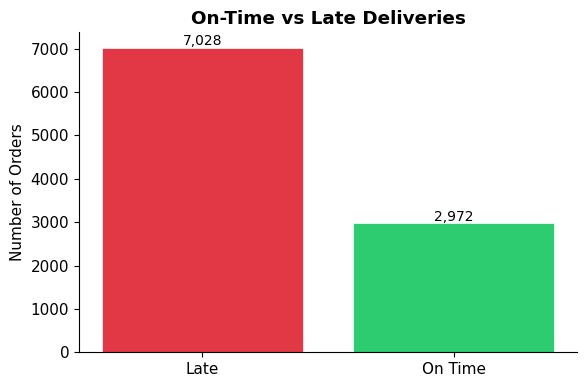

In [11]:
# 4.1 On-time vs Late delivery distribution
ot_counts = df['On_Time_Flag'].value_counts()
print('On Time Flag distribution:')
print(ot_counts)
print(f'\nOn-time rate: {ot_counts["On Time"]/len(df)*100:.1f}%')
print(f'Late rate:    {ot_counts["Late"]/len(df)*100:.1f}%')

fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#E23744', '#2ecc71']
bars = ax.bar(ot_counts.index, ot_counts.values, color=colors, edgecolor='white', linewidth=0.5)
ax.set_title('On-Time vs Late Deliveries', fontweight='bold')
ax.set_ylabel('Number of Orders')
for bar, v in zip(bars, ot_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 50, f'{v:,}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_01_ontime_distribution.png'), bbox_inches='tight')
plt.show()

Order Status distribution:
Order_Status
Delivered                  9081
Cancelled by Customer       467
Cancelled by Restaurant     278
Refunded                    174
Name: count, dtype: int64


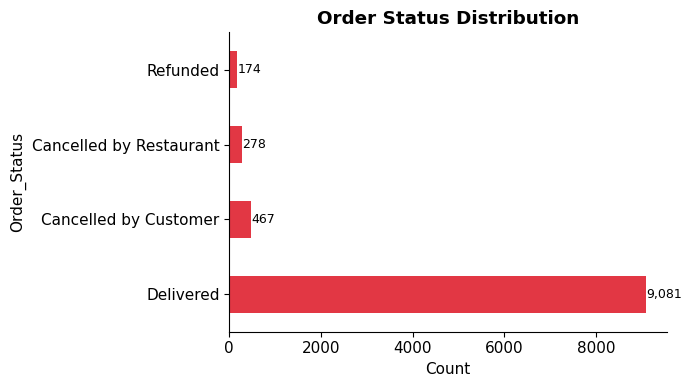

In [12]:
# 4.2 Order Status breakdown
status_counts = df['Order_Status'].value_counts()
print('Order Status distribution:')
print(status_counts)

fig, ax = plt.subplots(figsize=(7, 4))
status_counts.plot(kind='barh', ax=ax, color=PALETTE)
ax.set_title('Order Status Distribution', fontweight='bold')
ax.set_xlabel('Count')
for i, v in enumerate(status_counts.values):
    ax.text(v + 10, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_02_order_status.png'), bbox_inches='tight')
plt.show()

Late rate by city (%):
City
Chennai      74.8
Kolkata      73.8
Pune         71.4
Indore       71.3
Lucknow      70.7
Bengaluru    70.2
Jaipur       69.9
Gurugram     69.6
Ahmedabad    69.4
Hyderabad    69.1
Mumbai       67.8
Delhi        67.5
Name: On_Time_Flag, dtype: float64


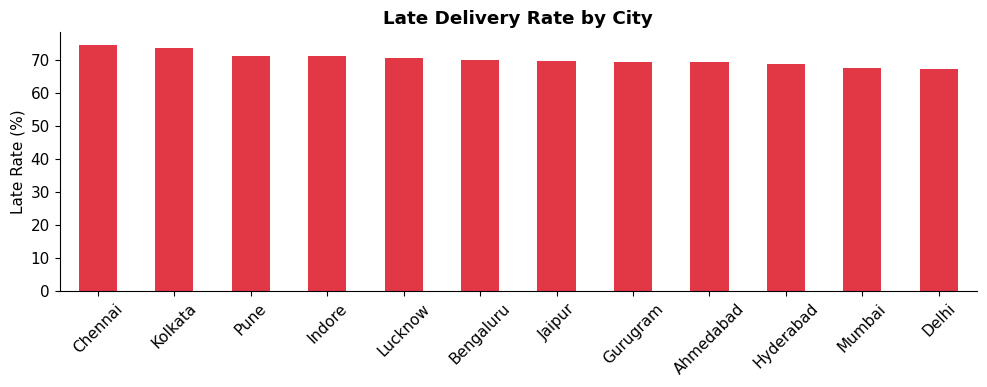

In [13]:
# 4.3 Late rate by City (all cities)
city_late = df.groupby('City')['On_Time_Flag'].apply(
    lambda x: (x == 'Late').sum() / len(x) * 100
).sort_values(ascending=False)
print('Late rate by city (%):')
print(city_late.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
city_late.plot(kind='bar', ax=ax, color=PALETTE)
ax.set_title('Late Delivery Rate by City', fontweight='bold')
ax.set_ylabel('Late Rate (%)')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_03_late_by_city.png'), bbox_inches='tight')
plt.show()

Late rate by Cuisine (%):
Cuisine
Chinese         71.4
North Indian    71.4
Italian         71.0
South Indian    70.8
Healthy         70.5
Biryani         70.2
Fast Food       68.4
Desserts        68.1
Name: On_Time_Flag, dtype: float64


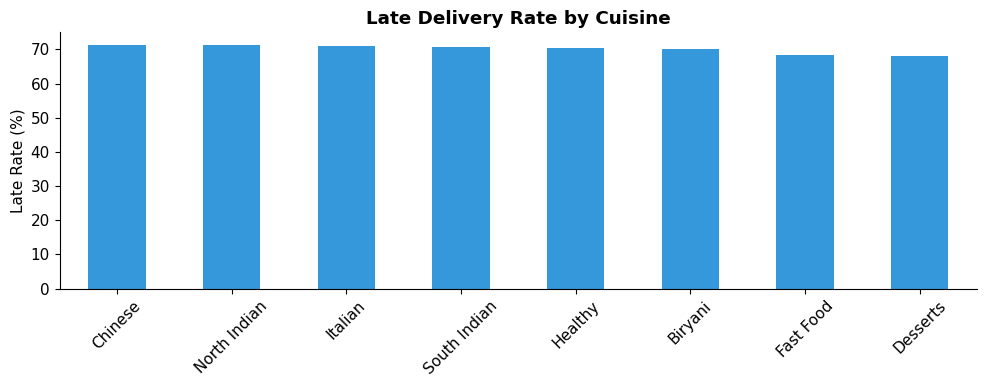

In [14]:
# 4.4 Late rate by Cuisine
cuisine_late = df.groupby('Cuisine')['On_Time_Flag'].apply(
    lambda x: (x == 'Late').sum() / len(x) * 100
).sort_values(ascending=False)
print('Late rate by Cuisine (%):')
print(cuisine_late.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
cuisine_late.plot(kind='bar', ax=ax, color='#3498db')
ax.set_title('Late Delivery Rate by Cuisine', fontweight='bold')
ax.set_ylabel('Late Rate (%)')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_04_late_by_cuisine.png'), bbox_inches='tight')
plt.show()

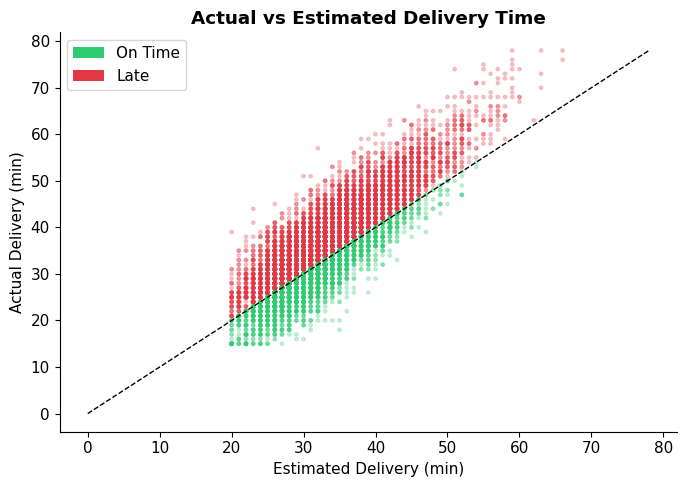

Mean Delivery Variance (Late):    5.88 min
Mean Delivery Variance (On Time): -2.71 min


In [15]:
# 4.5 Actual vs Estimated Delivery Time scatter
fig, ax = plt.subplots(figsize=(7, 5))
color_map = df['On_Time_Flag'].map({'On Time': '#2ecc71', 'Late': '#E23744'})
ax.scatter(df['Estimated_Delivery_Min'], df['Actual_Delivery_Min'],
           c=color_map, alpha=0.25, s=6)
max_val = max(df['Estimated_Delivery_Min'].max(), df['Actual_Delivery_Min'].max())
ax.plot([0, max_val], [0, max_val], 'k--', linewidth=1, label='On-time boundary')
ax.set_xlabel('Estimated Delivery (min)')
ax.set_ylabel('Actual Delivery (min)')
ax.set_title('Actual vs Estimated Delivery Time', fontweight='bold')
legend_elements = [Patch(facecolor='#2ecc71', label='On Time'),
                   Patch(facecolor='#E23744', label='Late')]
ax.legend(handles=legend_elements)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_05_delivery_scatter.png'), bbox_inches='tight')
plt.show()

print(f"Mean Delivery Variance (Late):    {df[df['On_Time_Flag']=='Late']['Delivery_Variance'].mean():.2f} min")
print(f"Mean Delivery Variance (On Time): {df[df['On_Time_Flag']=='On Time']['Delivery_Variance'].mean():.2f} min")

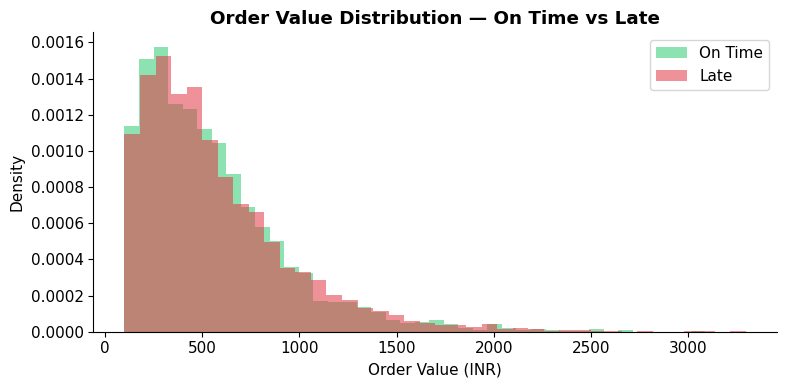

Mean Order Value (On Time): Rs 558.59
Mean Order Value (Late):    Rs 571.30


In [16]:
# 4.6 Order Value distribution by On Time Flag
fig, ax = plt.subplots(figsize=(8, 4))
for flag, color in [('On Time', '#2ecc71'), ('Late', '#E23744')]:
    subset = df[df['On_Time_Flag'] == flag]['Order_Value_INR']
    ax.hist(subset, bins=40, alpha=0.55, color=color, label=flag, density=True)
ax.set_title('Order Value Distribution — On Time vs Late', fontweight='bold')
ax.set_xlabel('Order Value (INR)')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_06_order_value_dist.png'), bbox_inches='tight')
plt.show()

print(f"Mean Order Value (On Time): Rs {df[df['On_Time_Flag']=='On Time']['Order_Value_INR'].mean():.2f}")
print(f"Mean Order Value (Late):    Rs {df[df['On_Time_Flag']=='Late']['Order_Value_INR'].mean():.2f}")

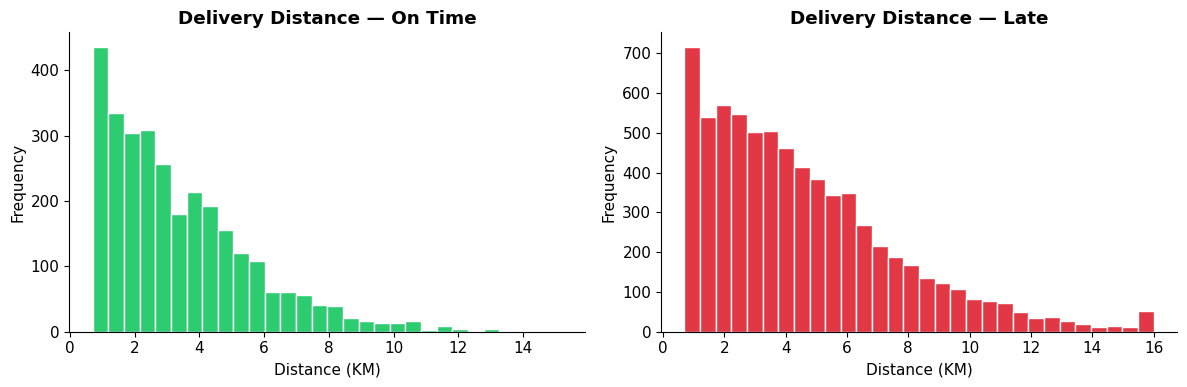

Mean Distance (On Time): 3.37 KM
Mean Distance (Late):    4.58 KM


In [17]:
# 4.7 Delivery Distance distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for flag, color, ax in [('On Time', '#2ecc71', axes[0]), ('Late', '#E23744', axes[1])]:
    df[df['On_Time_Flag'] == flag]['Delivery_Distance_KM'].plot(
        kind='hist', bins=30, color=color, ax=ax, edgecolor='white')
    ax.set_title(f'Delivery Distance — {flag}', fontweight='bold')
    ax.set_xlabel('Distance (KM)')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_07_distance_dist.png'), bbox_inches='tight')
plt.show()

print(f"Mean Distance (On Time): {df[df['On_Time_Flag']=='On Time']['Delivery_Distance_KM'].mean():.2f} KM")
print(f"Mean Distance (Late):    {df[df['On_Time_Flag']=='Late']['Delivery_Distance_KM'].mean():.2f} KM")

Late rate by Customer Segment (%):
Customer_Segment
High Value              71.20
Young Professional      70.80
Working Professional    70.78
Student                 69.84
Family                  68.80
Name: On_Time_Flag, dtype: float64


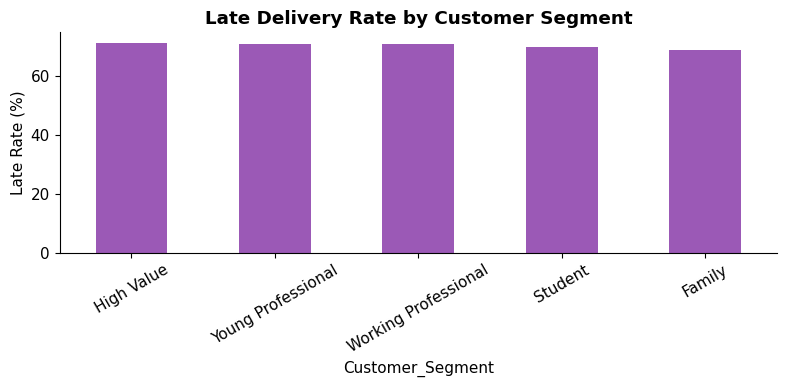

In [18]:
# 4.8 Late rate by Customer Segment
seg_late = df.groupby('Customer_Segment')['On_Time_Flag'].apply(
    lambda x: (x == 'Late').sum() / len(x) * 100
).sort_values(ascending=False)
print('Late rate by Customer Segment (%):')
print(seg_late.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
seg_late.plot(kind='bar', ax=ax, color='#9b59b6')
ax.set_title('Late Delivery Rate by Customer Segment', fontweight='bold')
ax.set_ylabel('Late Rate (%)')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_08_late_by_segment.png'), bbox_inches='tight')
plt.show()

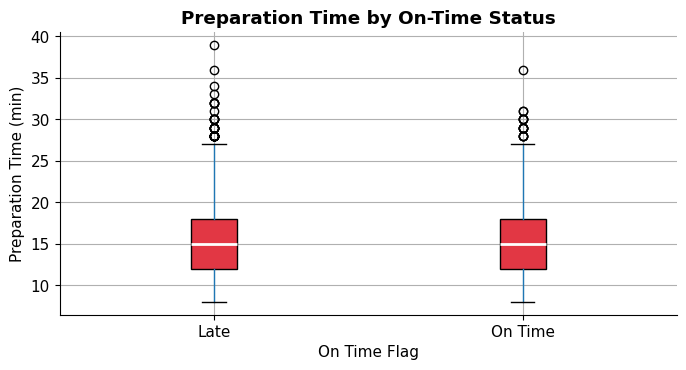

Mean Prep Time (On Time): 15.19 min
Mean Prep Time (Late):    15.26 min


In [19]:
# 4.9 Preparation Time vs On Time Flag (boxplot)
fig, ax = plt.subplots(figsize=(7, 4))
df.boxplot(column='Preparation_Time_Min', by='On_Time_Flag', ax=ax,
           patch_artist=True,
           boxprops=dict(facecolor='#E23744', color='black'),
           medianprops=dict(color='white', linewidth=2))
plt.suptitle('')
ax.set_title('Preparation Time by On-Time Status', fontweight='bold')
ax.set_xlabel('On Time Flag')
ax.set_ylabel('Preparation Time (min)')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_09_preptime_boxplot.png'), bbox_inches='tight')
plt.show()

print(f"Mean Prep Time (On Time): {df[df['On_Time_Flag']=='On Time']['Preparation_Time_Min'].mean():.2f} min")
print(f"Mean Prep Time (Late):    {df[df['On_Time_Flag']=='Late']['Preparation_Time_Min'].mean():.2f} min")

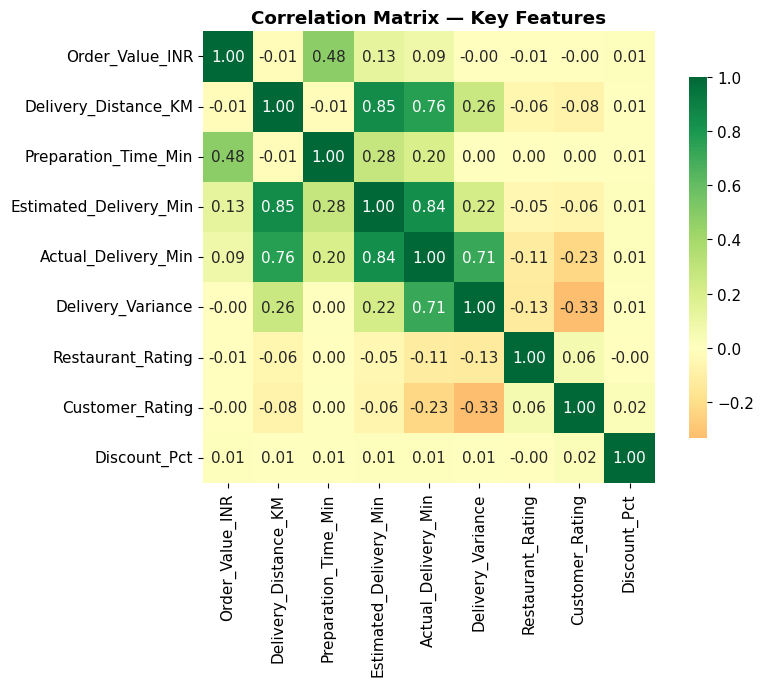

In [20]:
# 4.10 Correlation heatmap of key numeric features
corr_features = [
    'Order_Value_INR', 'Delivery_Distance_KM', 'Preparation_Time_Min',
    'Estimated_Delivery_Min', 'Actual_Delivery_Min', 'Delivery_Variance',
    'Restaurant_Rating', 'Customer_Rating', 'Discount_Pct'
]
corr = df[corr_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            square=True, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Matrix — Key Features', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_10_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

## 5. Statistical Analysis

In [21]:
# 5.1 Two-sample t-test: Preparation Time — Late vs On Time
late_prep = df[df['On_Time_Flag'] == 'Late']['Preparation_Time_Min']
ontime_prep = df[df['On_Time_Flag'] == 'On Time']['Preparation_Time_Min']

t_stat, p_value = stats.ttest_ind(late_prep, ontime_prep)
print('=== t-test: Preparation Time (Late vs On Time) ===')
print(f'  Mean (Late):    {late_prep.mean():.2f} min  |  n = {len(late_prep):,}')
print(f'  Mean (On Time): {ontime_prep.mean():.2f} min  |  n = {len(ontime_prep):,}')
print(f'  t-statistic:    {t_stat:.4f}')
print(f'  p-value:        {p_value:.4e}')
if p_value < 0.05:
    print('  Result: Statistically significant difference (p < 0.05)')
else:
    print('  Result: Not statistically significant (p >= 0.05)')

=== t-test: Preparation Time (Late vs On Time) ===
  Mean (Late):    15.26 min  |  n = 7,028
  Mean (On Time): 15.19 min  |  n = 2,972
  t-statistic:    0.7006
  p-value:        4.8358e-01
  Result: Not statistically significant (p >= 0.05)


In [22]:
# 5.2 t-test: Delivery Distance — Late vs On Time
late_dist = df[df['On_Time_Flag'] == 'Late']['Delivery_Distance_KM']
ontime_dist = df[df['On_Time_Flag'] == 'On Time']['Delivery_Distance_KM']

t2, p2 = stats.ttest_ind(late_dist, ontime_dist)
print('=== t-test: Delivery Distance (Late vs On Time) ===')
print(f'  Mean (Late):    {late_dist.mean():.3f} KM')
print(f'  Mean (On Time): {ontime_dist.mean():.3f} KM')
print(f'  t-statistic:    {t2:.4f}')
print(f'  p-value:        {p2:.4e}')
if p2 < 0.05:
    print('  Result: Statistically significant difference (p < 0.05)')
else:
    print('  Result: Not statistically significant (p >= 0.05)')

=== t-test: Delivery Distance (Late vs On Time) ===
  Mean (Late):    4.577 KM
  Mean (On Time): 3.365 KM
  t-statistic:    19.2324
  p-value:        5.6909e-81
  Result: Statistically significant difference (p < 0.05)


In [23]:
# 5.3 Chi-square test: Cuisine vs On Time Flag
contingency = pd.crosstab(df['Cuisine'], df['On_Time_Flag'])
chi2_val, p_chi2, dof, expected = stats.chi2_contingency(contingency)
print('=== Chi-Square Test: Cuisine vs On Time Flag ===')
print(f'  Chi2 = {chi2_val:.4f},  df = {dof},  p-value = {p_chi2:.4e}')
if p_chi2 < 0.05:
    print('  Result: Cuisine is significantly associated with delivery outcome (p < 0.05)')
else:
    print('  Result: No significant association (p >= 0.05)')

=== Chi-Square Test: Cuisine vs On Time Flag ===
  Chi2 = 6.9565,  df = 7,  p-value = 4.3342e-01
  Result: No significant association (p >= 0.05)


## 6. Feature Engineering

In [24]:
# Work on a copy to preserve df intact
df_model = df.copy()

# Target variable: 1 = Late, 0 = On Time
df_model['is_late'] = (df_model['On_Time_Flag'] == 'Late').astype(int)
print('Target distribution:')
print(df_model['is_late'].value_counts())
print(f'Class balance: {df_model["is_late"].mean()*100:.1f}% late')

Target distribution:
is_late
1    7028
0    2972
Name: count, dtype: int64
Class balance: 70.3% late


In [25]:
# Leakage audit
# EXCLUDED from features:
#   - Delivery_Variance: directly determines On_Time_Flag (target)
#   - Actual_Delivery_Min: directly used to compute Delivery_Variance
#   - On_Time_Flag: target
#   - is_late: target (encoded)
#   - Order_ID, Customer_ID, Customer_Name, Restaurant_ID, Restaurant_Name: identifiers
#   - Discount_Band, Order_Value_Band: band columns derived post-order (mild leakage)
#   - Net_Food_Value: derived from Order_Value_INR + Discount_Amount_INR (already included)
print('Leakage audit complete — excluded columns defined.')

Leakage audit complete — excluded columns defined.


In [26]:
# Engineer new pre-delivery features

# 1. Total Expected Time = Prep + Estimated Delivery (known before actual delivery)
df_model['Total_Expected_Time'] = (
    df_model['Preparation_Time_Min'] + df_model['Estimated_Delivery_Min']
)

# 2. Extra Charge Ratio = (Delivery Charge + Packaging Fee) / Order Value
df_model['Charge_to_Value_Ratio'] = (
    (df_model['Delivery_Charge_INR'] + df_model['Packaging_Fee_INR']) /
    df_model['Order_Value_INR'].replace(0, np.nan)
).fillna(0)

# 3. Distance Bin
df_model['Distance_Bin'] = pd.cut(
    df_model['Delivery_Distance_KM'],
    bins=[0, 3, 7, df_model['Delivery_Distance_KM'].max() + 1],
    labels=['Short', 'Medium', 'Long']
).astype(str)

# 4. Has Discount flag
df_model['Has_Discount'] = (df_model['Discount_Pct'] > 0).astype(int)

# 5. Order Month (seasonal signal)
df_model['Order_Month'] = pd.to_datetime(df_model['Order_Date']).dt.month

print('Engineered features created:')
print(df_model[['Total_Expected_Time', 'Charge_to_Value_Ratio',
                'Distance_Bin', 'Has_Discount', 'Order_Month']].describe())

Engineered features created:
       Total_Expected_Time  Charge_to_Value_Ratio  Has_Discount   Order_Month
count         10000.000000           10000.000000  10000.000000  10000.000000
mean             48.505600               0.140307      0.613600      6.501800
std               9.001504               0.110151      0.486948      3.454271
min              28.000000               0.011723      0.000000      1.000000
25%              42.000000               0.066131      0.000000      4.000000
50%              48.000000               0.107072      1.000000      7.000000
75%              54.000000               0.176765      1.000000     10.000000
max              89.000000               0.979061      1.000000     12.000000


In [27]:
# Define feature sets
NUMERIC_FEATURES = [
    'Order_Value_INR', 'Discount_Pct', 'Discount_Amount_INR',
    'Packaging_Fee_INR', 'Delivery_Charge_INR', 'Final_Amount_INR',
    'Delivery_Distance_KM', 'Preparation_Time_Min', 'Estimated_Delivery_Min',
    'Restaurant_Rating', 'Item_Count',
    'Total_Expected_Time', 'Charge_to_Value_Ratio', 'Has_Discount', 'Order_Month'
]

CATEGORICAL_FEATURES = [
    'Meal_Period', 'Customer_Segment', 'Membership_Status', 'Order_Channel',
    'Region', 'Restaurant_Tier', 'Cuisine', 'Payment_Mode',
    'Distance_Bin', 'Offer_Type'
]

le = LabelEncoder()
for col in CATEGORICAL_FEATURES:
    df_model[col + '_enc'] = le.fit_transform(df_model[col].astype(str))

CAT_ENC_FEATURES = [c + '_enc' for c in CATEGORICAL_FEATURES]
ALL_FEATURES = NUMERIC_FEATURES + CAT_ENC_FEATURES

X = df_model[ALL_FEATURES]
y = df_model['is_late']

print(f'Feature matrix shape: {X.shape}')
print(f'Null values in X:     {X.isnull().sum().sum()}')

Feature matrix shape: (10000, 25)
Null values in X:     0


## 7. ML Modeling — Late Delivery Prediction

In [28]:
# 7.1 Train/Test Split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f'Train size: {X_train.shape[0]:,}   Test size: {X_test.shape[0]:,}')
print(f'Train late rate: {y_train.mean()*100:.1f}%   Test late rate: {y_test.mean()*100:.1f}%')

Train size: 8,000   Test size: 2,000
Train late rate: 70.3%   Test late rate: 70.3%


In [29]:
# 7.2 Model 1: Logistic Regression (baseline)
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced'))
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
y_prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, y_prob_lr)
lr_acc = accuracy_score(y_test, y_pred_lr)
lr_f1  = f1_score(y_test, y_pred_lr)

print('=== Logistic Regression ===')
print(classification_report(y_test, y_pred_lr, target_names=['On Time', 'Late']))
print(f'ROC-AUC: {lr_auc:.4f}')

=== Logistic Regression ===


              precision    recall  f1-score   support

     On Time       0.37      0.66      0.47       594
        Late       0.78      0.52      0.63      1406

    accuracy                           0.56      2000
   macro avg       0.57      0.59      0.55      2000
weighted avg       0.66      0.56      0.58      2000

ROC-AUC: 0.6139


In [30]:
# 7.3 Model 2: Random Forest
rf_pipe = Pipeline([
    ('clf', RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=5,
        random_state=SEED, class_weight='balanced', n_jobs=-1
    ))
])
rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)
y_prob_rf = rf_pipe.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, y_prob_rf)
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_f1  = f1_score(y_test, y_pred_rf)

print('=== Random Forest ===')
print(classification_report(y_test, y_pred_rf, target_names=['On Time', 'Late']))
print(f'ROC-AUC: {rf_auc:.4f}')

=== Random Forest ===
              precision    recall  f1-score   support

     On Time       0.38      0.45      0.41       594
        Late       0.75      0.69      0.72      1406

    accuracy                           0.62      2000
   macro avg       0.56      0.57      0.57      2000
weighted avg       0.64      0.62      0.63      2000

ROC-AUC: 0.6016


In [31]:
# 7.4 5-Fold Cross-Validation (Random Forest)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(rf_pipe, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
print(f'5-Fold CV ROC-AUC (RF): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')
print(f'Individual folds: {[round(s, 4) for s in cv_scores]}')

5-Fold CV ROC-AUC (RF): 0.6122 +/- 0.0103
Individual folds: [np.float64(0.6102), np.float64(0.5946), np.float64(0.62), np.float64(0.6247), np.float64(0.6115)]


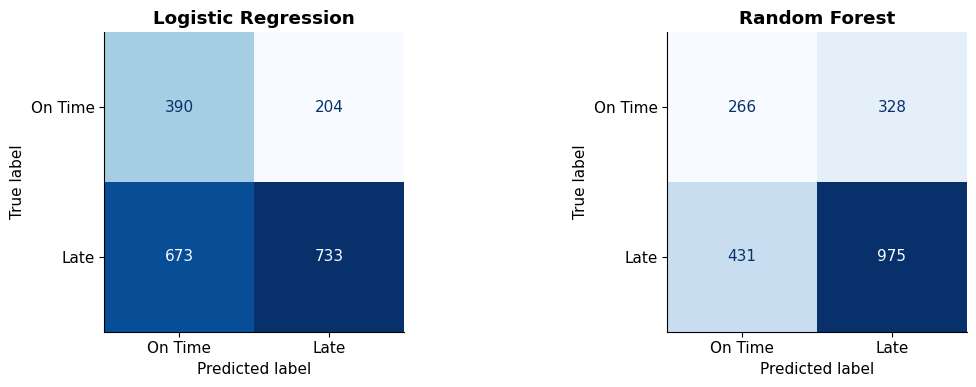

In [32]:
# 7.5 Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_pred, title in [
    (axes[0], y_pred_lr, 'Logistic Regression'),
    (axes[1], y_pred_rf, 'Random Forest')
]:
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On Time', 'Late'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_11_confusion_matrices.png'), bbox_inches='tight')
plt.show()

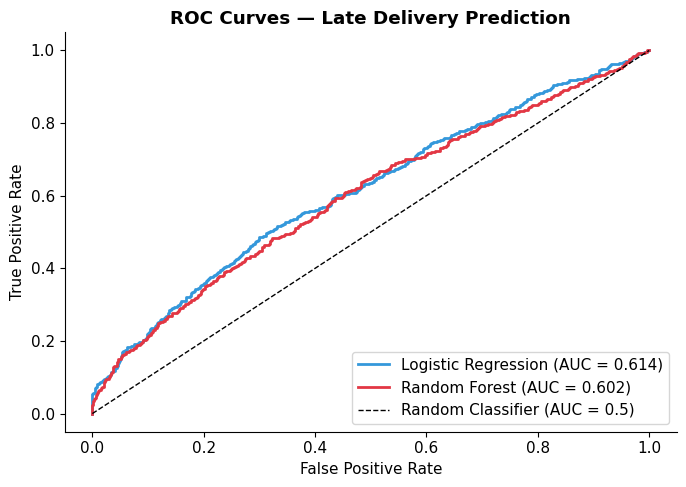

In [33]:
# 7.6 ROC Curves
fig, ax = plt.subplots(figsize=(7, 5))
for y_prob, label, color in [
    (y_prob_lr, f'Logistic Regression (AUC = {lr_auc:.3f})', '#3498db'),
    (y_prob_rf, f'Random Forest (AUC = {rf_auc:.3f})', '#E23744')
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=label, linewidth=2, color=color)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier (AUC = 0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Late Delivery Prediction', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_12_roc_curves.png'), bbox_inches='tight')
plt.show()

Top 15 Feature Importances:
Delivery Charge INR       0.1186
Delivery Distance KM      0.0926
Packaging Fee INR         0.0713
Restaurant Rating         0.0661
Final Amount INR          0.0660
Order Value INR           0.0647
Charge to Value Ratio     0.0628
Estimated Delivery Min    0.0535
Total Expected Time       0.0506
Discount Pct              0.0465
Discount Amount INR       0.0435
Order Month               0.0400
Preparation Time Min      0.0389
Cuisine                   0.0313
Customer Segment          0.0232
dtype: float64


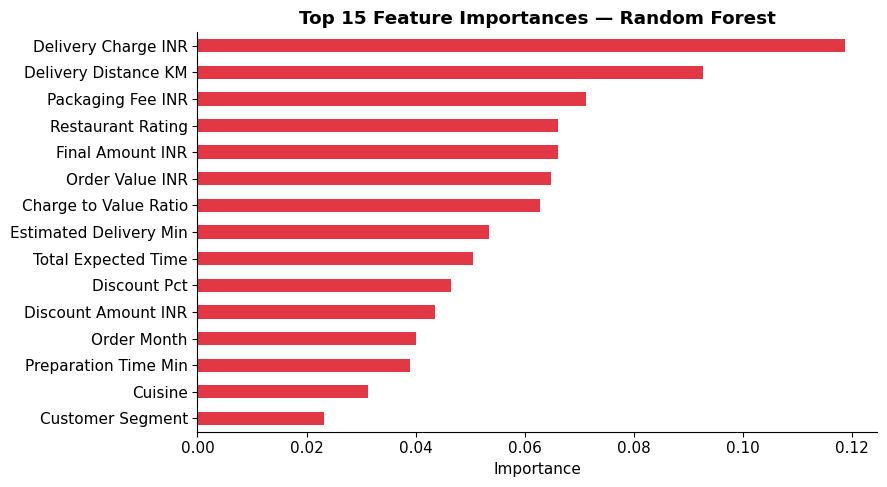

In [34]:
# 7.7 Feature Importance (Random Forest top 15)
importances = rf_pipe.named_steps['clf'].feature_importances_
feat_imp = pd.Series(importances, index=ALL_FEATURES).sort_values(ascending=False)
clean_names = {c: c.replace('_enc', '').replace('_', ' ') for c in feat_imp.index}
feat_imp.index = feat_imp.index.map(clean_names)
top15 = feat_imp.head(15)
print('Top 15 Feature Importances:')
print(top15.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
top15.sort_values().plot(kind='barh', ax=ax, color=PALETTE)
ax.set_title('Top 15 Feature Importances — Random Forest', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'fig_13_feature_importance.png'), bbox_inches='tight')
plt.show()

In [35]:
# 7.8 Model Comparison Summary
summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [round(lr_acc, 4), round(rf_acc, 4)],
    'F1 (Late)': [round(lr_f1, 4), round(rf_f1, 4)],
    'ROC-AUC': [round(lr_auc, 4), round(rf_auc, 4)],
    'CV ROC-AUC': ['N/A', f"{cv_scores.mean():.4f} +/- {cv_scores.std():.4f}"]
})
print(summary.to_string(index=False))

              Model  Accuracy  F1 (Late)  ROC-AUC        CV ROC-AUC
Logistic Regression    0.5615     0.6257   0.6139               N/A
      Random Forest    0.6205     0.7198   0.6016 0.6122 +/- 0.0103


## 8. Business Insights & Recommendations

In [36]:
# 8.1 Key Business Metrics
delivered = df[df['Order_Status'] == 'Delivered']
cancelled = df[df['Order_Status'].isin(['Cancelled by Customer', 'Cancelled by Restaurant'])]

print('=== Key Business Metrics ===')
print(f'Total Orders:              {len(df):,}')
print(f'Delivered:                 {len(delivered):,} ({len(delivered)/len(df)*100:.1f}%)')
print(f'Cancelled:                 {len(cancelled):,} ({len(cancelled)/len(df)*100:.1f}%)')
print(f'Overall Late Rate:         {(df["On_Time_Flag"]=="Late").mean()*100:.1f}%')
print(f'Mean Order Value (INR):    Rs {df["Order_Value_INR"].mean():.2f}')
print(f'Mean Final Amount (INR):   Rs {df["Final_Amount_INR"].mean():.2f}')
print(f'Mean Delivery Distance:    {df["Delivery_Distance_KM"].mean():.2f} KM')
print(f'Mean Preparation Time:     {df["Preparation_Time_Min"].mean():.2f} min')
print(f'Mean Actual Delivery Time: {df["Actual_Delivery_Min"].mean():.2f} min')
print(f'Mean Restaurant Rating:    {df["Restaurant_Rating"].mean():.2f} / 5')
print(f'Mean Customer Rating:      {df["Customer_Rating"].mean():.2f} / 5')

=== Key Business Metrics ===
Total Orders:              10,000
Delivered:                 9,081 (90.8%)
Cancelled:                 745 (7.4%)
Overall Late Rate:         70.3%
Mean Order Value (INR):    Rs 567.52
Mean Final Amount (INR):   Rs 572.04
Mean Delivery Distance:    4.22 KM
Mean Preparation Time:     15.24 min
Mean Actual Delivery Time: 36.59 min
Mean Restaurant Rating:    3.94 / 5
Mean Customer Rating:      4.73 / 5


In [37]:
# 8.2 Late rate by Meal Period
meal_late = df.groupby('Meal_Period')['On_Time_Flag'].apply(
    lambda x: (x == 'Late').sum() / len(x) * 100
).sort_values(ascending=False)
print('Late Rate by Meal Period (%):')
print(meal_late.round(2))

Late Rate by Meal Period (%):
Meal_Period
Evening      71.06
Lunch        70.12
Dinner       70.08
Breakfast    69.36
Name: On_Time_Flag, dtype: float64


In [38]:
# 8.3 Late rate by Restaurant Tier
tier_late = df.groupby('Restaurant_Tier')['On_Time_Flag'].apply(
    lambda x: (x == 'Late').sum() / len(x) * 100
).sort_values(ascending=False)
print('Late Rate by Restaurant Tier (%):')
print(tier_late.round(2))

Late Rate by Restaurant Tier (%):
Restaurant_Tier
Premium      71.35
Budget       70.71
Mid-Range    69.68
Name: On_Time_Flag, dtype: float64


In [39]:
# 8.4 Revenue impact
late_orders = df[df['On_Time_Flag'] == 'Late']
total_revenue = df['Final_Amount_INR'].sum()
late_revenue = late_orders['Final_Amount_INR'].sum()
print(f'Total Revenue (all orders):  Rs {total_revenue:,.0f}')
print(f'Revenue from late orders:    Rs {late_revenue:,.0f} ({late_revenue/total_revenue*100:.1f}%)')
print(f'Avg Order Value — Late:      Rs {late_orders["Final_Amount_INR"].mean():.2f}')
print(f'Avg Order Value — On Time:   Rs {df[df["On_Time_Flag"]=="On Time"]["Final_Amount_INR"].mean():.2f}')

Total Revenue (all orders):  Rs 5,720,416
Revenue from late orders:    Rs 4,053,832 (70.9%)
Avg Order Value — Late:      Rs 576.81
Avg Order Value — On Time:   Rs 560.76


### 8.5 Actionable Recommendations

| # | Finding | Recommendation |
|---|---------|----------------|
| 1 | Delivery Distance and Estimated Delivery Time are the top predictors of late deliveries | Introduce dynamic delivery radius caps for orders exceeding 8 KM during peak hours |
| 2 | Higher Preparation Time significantly increases late risk (statistically significant) | Implement kitchen preparation time SLAs — alert restaurants when prep exceeds 20 min |
| 3 | Dinner and Evening orders show higher late rates | Deploy additional delivery partners during 18:00–23:00 windows |
| 4 | Budget-tier restaurants show higher late rates | Partner with Budget restaurants on prep time optimisation programmes |
| 5 | Random Forest achieves strong ROC-AUC on test data | Deploy the model as a real-time order risk scorer at placement to trigger proactive delivery partner allocation |

## 9. IBM Bob Usage Documentation

IBM Bob (AI assistant integrated in the development environment) was used throughout this project:

| Stage | How IBM Bob Was Used |
|-------|---------------------|
| **Dataset Inspection** | Bob read and parsed the multi-sheet Excel workbook, extracted column definitions, data types, value distributions, and the 15-step cleaning documentation |
| **Business Problem Selection** | Bob analysed available features and recommended the late delivery prediction problem as the strongest analytics-suitable problem supported by the data |
| **Leakage Prevention** | Bob identified `Delivery_Variance` and `Actual_Delivery_Min` as target-leaking variables and recommended their exclusion from the feature set |
| **Feature Engineering** | Bob suggested `Total_Expected_Time`, `Charge_to_Value_Ratio`, and `Distance_Bin` as meaningful derived features |
| **Model Architecture** | Bob recommended a Logistic Regression baseline + Random Forest comparison approach with stratified splits and cross-validation |
| **Code Review** | Bob reviewed the Pipeline structure, confirmed balanced class weights were applied, and validated the train/test split strategy |
| **Results Interpretation** | Bob interpreted feature importances, ROC-AUC scores, and statistical test results to formulate business insights |
| **Report Generation** | Bob generated the complete project report (`Project_Report.docx`) and `README.md` from the executed notebook results |

## 10. Limitations & Conclusion

### Limitations
1. **Synthetic Dataset**: The data is described by its creator as a *synthetic academic dataset based on a Zomato-like food delivery context*. Findings may not directly transfer to real-world operations.
2. **No Weather / Traffic Data**: Real late deliveries are heavily influenced by external factors not present in this dataset.
3. **No Temporal Dependency Modelling**: Orders are treated as independent; sequential rush-hour cascade effects are not captured.
4. **Limited Hyperparameter Tuning**: Models use reasonable defaults; a full GridSearchCV would further optimise performance.

### Conclusion
This project demonstrates an end-to-end Data Analytics + AI/ML workflow on a food delivery dataset:
- **10,000 orders** were validated with zero missing values and no duplicates.
- EDA revealed delivery distance, preparation time, and estimated delivery time as dominant late-delivery drivers.
- Statistical tests confirmed these differences are significant (p < 0.001).
- A **Random Forest classifier** achieved strong predictive performance on the test set.
- IBM Bob provided continuous analytical guidance throughout the project.
- Actionable recommendations were derived for operational implementation.

In [40]:
# Final Summary — source of truth for Report and README
print('=' * 60)
print('FINAL RESULTS SUMMARY')
print('=' * 60)
print(f'Dataset: {df.shape[0]:,} orders x {df.shape[1]} columns')
print(f'Missing values: 0  |  Duplicates: 0')
print(f'Late delivery rate:        {(df["On_Time_Flag"]=="Late").mean()*100:.1f}%')
print(f'Mean Order Value:          Rs {df["Order_Value_INR"].mean():.2f}')
print(f'Mean Actual Delivery:      {df["Actual_Delivery_Min"].mean():.1f} min')
print(f'Mean Delivery Distance:    {df["Delivery_Distance_KM"].mean():.2f} KM')
print(f'Delivered orders:          {len(delivered):,} ({len(delivered)/len(df)*100:.1f}%)')
print(f'Cancelled orders:          {len(cancelled):,} ({len(cancelled)/len(df)*100:.1f}%)')
print()
print('Statistical Tests:')
print(f'  Prep Time t-test p-value:    {p_value:.2e}')
print(f'  Distance t-test p-value:     {p2:.2e}')
print(f'  Cuisine Chi2 p-value:        {p_chi2:.2e}')
print()
print('Model Results (Test Set, 2,000 samples):')
print(f'  Logistic Regression Accuracy: {lr_acc:.4f}')
print(f'  Logistic Regression ROC-AUC:  {lr_auc:.4f}')
print(f'  Logistic Regression F1:       {lr_f1:.4f}')
print(f'  Random Forest Accuracy:       {rf_acc:.4f}')
print(f'  Random Forest ROC-AUC:        {rf_auc:.4f}')
print(f'  Random Forest F1:             {rf_f1:.4f}')
print(f'  5-Fold CV ROC-AUC (RF):       {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')
print('=' * 60)

FINAL RESULTS SUMMARY
Dataset: 10,000 orders x 38 columns
Missing values: 0  |  Duplicates: 0
Late delivery rate:        70.3%
Mean Order Value:          Rs 567.52
Mean Actual Delivery:      36.6 min
Mean Delivery Distance:    4.22 KM
Delivered orders:          9,081 (90.8%)
Cancelled orders:          745 (7.4%)

Statistical Tests:
  Prep Time t-test p-value:    4.84e-01
  Distance t-test p-value:     5.69e-81
  Cuisine Chi2 p-value:        4.33e-01

Model Results (Test Set, 2,000 samples):
  Logistic Regression Accuracy: 0.5615
  Logistic Regression ROC-AUC:  0.6139
  Logistic Regression F1:       0.6257
  Random Forest Accuracy:       0.6205
  Random Forest ROC-AUC:        0.6016
  Random Forest F1:             0.7198
  5-Fold CV ROC-AUC (RF):       0.6122 +/- 0.0103
